# 04 · Modelo Preditivo: antecipando o NPS antes da pesquisa

Fases 4, 5 e 6 do CRISP-DM (*Modeling*, *Evaluation* e *Deployment*).

**Pergunta que o modelo responde:**
> *"Com o que já sabemos sobre este pedido hoje (entrega, atraso, contatos, reclamações), qual nota esse cliente tende a dar, e ele precisa de uma ação agora?"*

## Estratégia adotada

| Decisão | Escolha | Justificativa técnica | Justificativa de negócio |
|---|---|---|---|
| **Tipo de problema** | **Regressão** da nota (0-10) como modelo principal; a nota prevista vira **faixas de risco**. Uma **classificação** (detrator × não detrator) é treinada para comparação | A nota contínua guarda mais informação que uma classe (6,9 e 0,5 são detratores muito diferentes) | Permite **priorizar** (quem está pior primeiro) e falar a língua do NPS |
| **Variáveis de entrada** | Só dados disponíveis **antes** da pesquisa (cliente, pedido, logística, atendimento) | Evita vazamento de informação (*data leakage*) | O modelo precisa funcionar no momento em que a ação ainda é possível |
| **Variáveis excluídas** | `csat_internal_score`, `repeat_purchase_30d` e IDs | São medidas coletadas junto ou depois do NPS; IDs não têm significado | Um modelo que usa a recompra futura para prever a nota é inútil na operação |
| **Separação dos dados** | Treino 80% / teste 20%, estratificado pela categoria NPS, mais validação cruzada de 5 dobras no treino | O teste "guardado" mede o desempenho em dados nunca vistos; a estratificação mantém a proporção de promotores (só 4%) | Estimativa honesta de como o modelo vai se sair em pedidos novos |
| **Modelos comparados** | Baseline (média) → Regressão Linear → Árvore de Decisão → Random Forest | Começar simples e só aumentar a complexidade se houver ganho real ("simple is better than complex") | Um modelo explicável gera confiança e é adotado pelas áreas |
| **Avaliação** | MAE, MSE, RMSE e R² (regressão); precisão, *recall*, F1 e AUC (classificação); % real de detratores por faixa de risco | Métricas complementares, como nas aulas de Estatística e Metas Analíticas | MAE = "erro médio em pontos de nota"; *recall* = "de cada 100 detratores, quantos o modelo avisa antes" |

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    classification_report, confusion_matrix, mean_absolute_error, mean_squared_error, r2_score, roc_auc_score,
)
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.tree import DecisionTreeRegressor

from src.funcoes_nps import (
    COLUNAS_POS_PESQUISA, LIMITE_DETRATOR, NOMES_AMIGAVEIS, PASTA_MODELOS, SEMENTE_ALEATORIA,
    calcular_nps, carregar_dados_tratados, classificar_nps,
)
from src.graficos import COR_AZUL, COR_CINZA, COR_VERMELHA, configurar_estilo, rotular_barras, salvar_figura
from src.modelo import pontuar_pedidos, preparar_variaveis

configurar_estilo()
dados = carregar_dados_tratados()

## 1. Variável alvo e variáveis de entrada

- **Alvo principal (regressão):** `nps_score`, nota de 0 a 10;
- **Alvo de comparação (classificação):** `e_detrator` = 1 se a nota for menor que 7.

As variáveis de entrada são as 13 colunas operacionais disponíveis antes da pesquisa. A região, que é texto, vira colunas 0/1 (*one-hot encoding*), com o Centro-Oeste como referência.

In [2]:
variaveis_entrada = preparar_variaveis(dados)
nota = dados["nps_score"]
e_detrator = dados["e_detrator"]

print(f"{variaveis_entrada.shape[1]} variáveis de entrada:")
print(list(variaveis_entrada.columns))

17 variáveis de entrada:
['customer_age', 'customer_tenure_months', 'order_value', 'items_quantity', 'discount_value', 'payment_installments', 'delivery_time_days', 'delivery_delay_days', 'freight_value', 'delivery_attempts', 'customer_service_contacts', 'resolution_time_days', 'complaints_count', 'regiao_Nordeste', 'regiao_Norte', 'regiao_Sudeste', 'regiao_Sul']


## 2. Separação treino / teste

In [3]:
# stratify: mantém a mesma proporção de detratores/neutros/promotores no treino e no teste
X_treino, X_teste, y_treino, y_teste = train_test_split(
    variaveis_entrada, nota, test_size=0.2, random_state=SEMENTE_ALEATORIA, stratify=dados["categoria_nps"]
)
print(f"Treino: {len(X_treino)} pedidos | Teste: {len(X_teste)} pedidos")
pd.DataFrame({
    "treino (%)": classificar_nps(y_treino).value_counts(normalize=True).sort_index() * 100,
    "teste (%)": classificar_nps(y_teste).value_counts(normalize=True).sort_index() * 100,
}).round(1)

Treino: 2000 pedidos | Teste: 500 pedidos


,treino (%),teste (%)
nps_score,,
Detrator,84.4,84.4
Neutro,11.2,11.2
Promotor,4.4,4.4


> **Sobre a separação:** a base não tem data do pedido, então a separação é aleatória. Em produção, o correto seria uma **separação temporal** (treinar com meses passados e testar no mês seguinte), simulando o uso real.

## 3. Comparação de modelos (validação cruzada no treino)

Na validação cruzada, o treino é dividido em 5 partes: o modelo treina em 4 e é avaliado na 5ª, repetindo 5 vezes. A métrica é o **MAE** (erro absoluto médio, em pontos de nota).

In [4]:
# Baseline: "chutar" sempre a nota média do treino, para todo mundo
mae_baseline = mean_absolute_error(y_treino, np.full(len(y_treino), y_treino.mean()))

modelos_candidatos = {
    "Regressão Linear": LinearRegression(),
    "Árvore de Decisão": DecisionTreeRegressor(max_depth=4, random_state=SEMENTE_ALEATORIA),
    "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=SEMENTE_ALEATORIA, n_jobs=-1),
}

resultados = [{"modelo": "Baseline (média)", "MAE médio (pontos)": mae_baseline, "desvio entre dobras": 0.0}]
for nome, modelo in modelos_candidatos.items():
    # cross_val_score devolve o MAE com sinal negativo (convenção do scikit-learn), por isso o "-"
    mae_por_dobra = -cross_val_score(modelo, X_treino, y_treino, cv=5, scoring="neg_mean_absolute_error")
    resultados.append({"modelo": nome, "MAE médio (pontos)": mae_por_dobra.mean(), "desvio entre dobras": mae_por_dobra.std()})

comparacao_modelos = pd.DataFrame(resultados).set_index("modelo").round(3)
comparacao_modelos

,MAE médio (pontos),desvio entre dobras
modelo,,
Baseline (média),2.039,0.000
Regressão Linear,1.309,0.061
Árvore de Decisão,1.433,0.022
Random Forest,1.356,0.050


**Leitura:**

- O **baseline** (chutar sempre a nota média) erra, em média, cerca de 2 pontos;
- A **Regressão Linear** reduz o erro para ~1,3 ponto;
- A **Árvore de Decisão** e o **Random Forest**, mais complexos, **não superam** a regressão linear. Isso indica que a relação entre operação e nota é essencialmente **linear e aditiva**, o que a EDA já sugeria (cada dia de atraso tira aproximadamente o mesmo tanto da nota).

**Escolha: Regressão Linear.** Ela tem o menor erro e ainda vence em **explicabilidade, estabilidade e facilidade de manutenção**: poder dizer *quanto* cada fator pesa vale mais do que qualquer ganho marginal de um modelo "caixa-preta".

## 4. O teste do vazamento de informação

Para mostrar por que excluímos `csat_internal_score` e `repeat_purchase_30d`, treinamos a mesma regressão **com** elas:

In [5]:
X_treino_com_vazamento = X_treino.join(dados.loc[X_treino.index, COLUNAS_POS_PESQUISA])
mae_sem_vazamento = -cross_val_score(LinearRegression(), X_treino, y_treino, cv=5, scoring="neg_mean_absolute_error").mean()
mae_com_vazamento = -cross_val_score(LinearRegression(), X_treino_com_vazamento, y_treino, cv=5, scoring="neg_mean_absolute_error").mean()
r2_sem_vazamento = cross_val_score(LinearRegression(), X_treino, y_treino, cv=5, scoring="r2").mean()
r2_com_vazamento = cross_val_score(LinearRegression(), X_treino_com_vazamento, y_treino, cv=5, scoring="r2").mean()

pd.DataFrame({
    "Sem vazamento (só pré-pesquisa)": [mae_sem_vazamento, r2_sem_vazamento],
    "Com CSAT + recompra (vazamento)": [mae_com_vazamento, r2_com_vazamento],
}, index=["MAE (pontos)", "R²"]).round(3)

,Sem vazamento (só pré-pesquisa),Com CSAT + recompra (vazamento)
MAE (pontos),1.309,1.18
R²,0.565,0.65


O modelo "com vazamento" parece melhor (o R² sobe de ~0,57 para ~0,65), mas **é uma ilusão**: na hora em que precisamos da previsão, a recompra em 30 dias ainda não aconteceu e o CSAT ainda não foi respondido. É exatamente a armadilha descrita na apostila de definição de target: *"é como se o modelo tivesse acesso ao futuro"*.

## 5. Treino final e avaliação no conjunto de teste

In [6]:
modelo_final = LinearRegression().fit(X_treino, y_treino)
nota_prevista_teste = np.clip(modelo_final.predict(X_teste), 0, 10)

mae = mean_absolute_error(y_teste, nota_prevista_teste)
mse = mean_squared_error(y_teste, nota_prevista_teste)
rmse = np.sqrt(mse)
r2 = r2_score(y_teste, nota_prevista_teste)
mae_baseline_teste = mean_absolute_error(y_teste, np.full(len(y_teste), y_treino.mean()))

print(f"MAE  (erro absoluto médio): {mae:.2f} pontos   (baseline: {mae_baseline_teste:.2f})")
print(f"MSE  (erro quadrático médio): {mse:.2f}")
print(f"RMSE (raiz do MSE): {rmse:.2f} pontos")
print(f"R²   (variação explicada): {r2:.2f}")

MAE  (erro absoluto médio): 1.39 pontos   (baseline: 2.11)
MSE  (erro quadrático médio): 3.17
RMSE (raiz do MSE): 1.78 pontos
R²   (variação explicada): 0.51


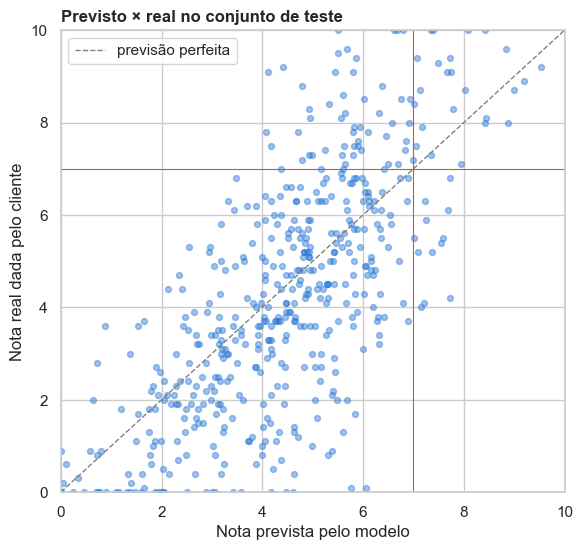

In [7]:
figura, eixo = plt.subplots(figsize=(6.5, 6))
eixo.scatter(nota_prevista_teste, y_teste, s=18, alpha=0.45, color=COR_AZUL)
eixo.plot([0, 10], [0, 10], color="gray", linestyle="--", linewidth=1, label="previsão perfeita")
eixo.axhline(LIMITE_DETRATOR, color=COR_VERMELHA, linewidth=0.8)
eixo.axvline(LIMITE_DETRATOR, color=COR_VERMELHA, linewidth=0.8)
eixo.set_xlim(0, 10)
eixo.set_ylim(0, 10)
eixo.set_xlabel("Nota prevista pelo modelo")
eixo.set_ylabel("Nota real dada pelo cliente")
eixo.set_title("Previsto × real no conjunto de teste")
eixo.legend(loc="upper left")
salvar_figura(figura, "11_previsto_vs_real.png")
plt.show()

No teste (500 pedidos nunca vistos), o modelo erra em média **1,4 ponto** (contra 2,1 do baseline) e explica cerca de **metade** da variação da nota (R² ≈ 0,51), em linha com a validação cruzada, ou seja, sem sinais de *overfitting*. O RMSE (1,8) um pouco maior que o MAE mostra que existem alguns erros grandes: clientes que dão nota muito diferente do esperado por razões que não estão na base.

Repare que o modelo é "conservador" nos extremos: quase nunca prevê notas acima de 8,5, porque nada nos dados operacionais distingue um cliente "satisfeito" (8) de um "encantado" (10). Por isso, o melhor uso é **ordenar o risco**, e não contar "promotores previstos".

## 6. O que o modelo aprendeu: quanto cada fator pesa

Para interpretar a regressão usamos o `summary()` do **statsmodels**, como na Aula 3 de Estatística: ele mostra o coeficiente de cada variável, o erro padrão e o **p-valor** (H₀: o coeficiente é zero, ou seja, a variável não influencia a nota).

In [8]:
# Mesmo modelo (mínimos quadrados), agora com o resumo estatístico completo
X_treino_com_constante = sm.add_constant(X_treino)
modelo_statsmodels = sm.OLS(y_treino, X_treino_com_constante).fit()
print(modelo_statsmodels.summary())

                            OLS Regression Results                            
Dep. Variable:              nps_score   R-squared:                       0.573
Model:                            OLS   Adj. R-squared:                  0.569
Method:                 Least Squares   F-statistic:                     156.2
Date:                Mon, 12 Oct 2026   Prob (F-statistic):               0.00
Time:                        18:43:34   Log-Likelihood:                -3820.1
No. Observations:                2000   AIC:                             7676.
Df Residuals:                    1982   BIC:                             7777.
Df Model:                          17                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const                 

In [9]:
# Tabela simplificada: efeito de +1 unidade de cada variável na nota, em pontos
tabela_coeficientes = pd.DataFrame({
    "efeito na nota (+1 unidade)": modelo_statsmodels.params,
    "p_valor": modelo_statsmodels.pvalues,
}).drop(index="const")
tabela_coeficientes.index = [NOMES_AMIGAVEIS.get(nome, nome) for nome in tabela_coeficientes.index]
tabela_coeficientes["influencia? (p<0,05)"] = np.where(tabela_coeficientes["p_valor"] < 0.05, "sim", "não")
tabela_coeficientes.sort_values("efeito na nota (+1 unidade)").round(3)

,efeito na nota (+1 unidade),p_valor,"influencia? (p<0,05)"
Atraso na entrega (dias),-0.937,0.000,sim
Nº de reclamações,-0.374,0.000,sim
Contatos com o SAC,-0.353,0.000,sim
Tempo de resolução (dias),-0.140,0.000,sim
Frete (R$),-0.007,0.028,sim
Tempo de entrega (dias),-0.002,0.809,não
Desconto (R$),-0.001,0.630,não
Tempo de casa (meses),-0.001,0.586,não
Valor do pedido (R$),0.001,0.000,sim
Idade do cliente,0.001,0.555,não


O modelo confirma a EDA com números diretos:

| Fator | Efeito estimado na nota | Influencia? |
|---|---|---|
| +1 dia de atraso | **≈ −0,9 ponto** | sim |
| +1 reclamação | ≈ −0,4 ponto | sim |
| +1 contato com o SAC | ≈ −0,35 ponto | sim |
| +1 dia para resolver | ≈ −0,14 ponto | sim |
| Desconto, parcelas, itens, tempo de entrega, idade, tempo de casa, região | ≈ 0 | não (p > 0,05) |
| Valor do pedido, frete, tentativas de entrega | ≈ 0 (ex.: R$ 100 a mais no pedido = +0,05 ponto) | p < 0,05, mas **efeito prático desprezível** |

> **Cuidado com a multicolinearidade:** contatos com o SAC e reclamações andam juntos (correlação de 0,75, notebook 03). Os dois aparecem como significativos, mas o efeito de cada um deve ser lido em conjunto: são duas medidas do mesmo problema ("o cliente precisou acionar a empresa").

## 7. Avaliação na linguagem do negócio: faixas de risco

A operação não precisa da nota exata: precisa saber **em quem agir primeiro**. Convertemos a nota prevista em três faixas, no mesmo espírito das faixas de score dos casos vistos em aula:

| Faixa | Nota prevista | Ação sugerida |
|---|---|---|
| **Risco alto** | < 4 | Ação imediata e personalizada (contato humano, solução prioritária, compensação) |
| **Risco moderado** | 4 a < 7 | Ação preventiva automatizada (aviso proativo, novo prazo realista) |
| **Risco baixo** | ≥ 7 | Fluxo padrão; candidato a programa de indicação |

In [10]:
pedidos_teste_pontuados = pontuar_pedidos(modelo_final, dados.loc[X_teste.index])

resultado_por_faixa = pedidos_teste_pontuados.groupby("faixa_risco", observed=False).agg(
    pedidos=("nps_score", "size"),
    nota_real_media=("nps_score", "mean"),
    pct_detratores_reais=("e_detrator", lambda x: 100 * x.mean()),
    pct_promotores_reais=("nps_score", lambda x: 100 * (x >= 9).mean()),
).round(1)
resultado_por_faixa["% dos pedidos"] = (100 * resultado_por_faixa["pedidos"] / resultado_por_faixa["pedidos"].sum()).round(1)
resultado_por_faixa

,pedidos,nota_real_media,pct_detratores_reais,pct_promotores_reais,% dos pedidos
faixa_risco,,,,,
Risco alto,175,2.2,100.0,0.0,35.0
Risco moderado,288,5.0,81.6,3.8,57.6
Risco baixo,37,7.6,32.4,29.7,7.4


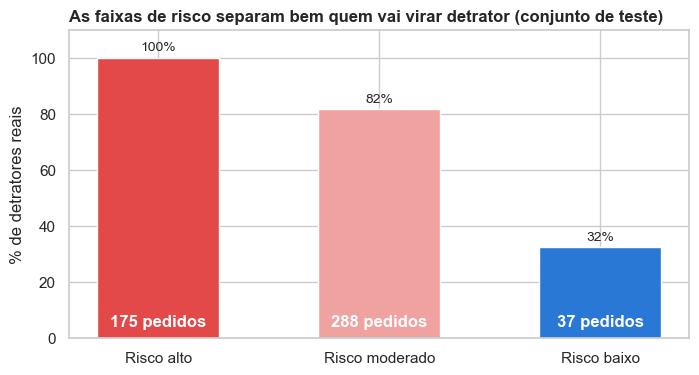

In [11]:
figura, eixo = plt.subplots(figsize=(8, 4))
eixo.bar(resultado_por_faixa.index.astype(str), resultado_por_faixa["pct_detratores_reais"],
         color=[COR_VERMELHA, "#f0a2a1", COR_AZUL], width=0.55)
rotular_barras(eixo, sufixo="%")
for posicao, quantidade in enumerate(resultado_por_faixa["pedidos"]):
    eixo.text(posicao, 4, f"{quantidade} pedidos", ha="center", color="white", fontweight="bold")
eixo.set_ylim(0, 110)
eixo.set_ylabel("% de detratores reais")
eixo.set_title("As faixas de risco separam bem quem vai virar detrator (conjunto de teste)")
salvar_figura(figura, "12_faixas_de_risco.png")
plt.show()

As faixas funcionam como esperado: na faixa de **risco alto**, todos os clientes viraram de fato detratores; na de **risco baixo**, a proporção cai para cerca de um terço e aparecem os promotores. Isso dá à operação uma **fila priorizada** confiável.

## 8. Comparação: modelo de classificação (detrator × não detrator)

Aqui a pergunta muda para "este cliente vai ser detrator: sim ou não?". Usamos a **regressão logística**. Como 84% dos clientes são detratores, as classes estão **desbalanceadas**: usamos `class_weight="balanced"` (um "algoritmo sensível ao custo", como na apostila de target) para o modelo não aprender simplesmente a dizer "detrator" para todo mundo.

In [12]:
e_detrator_treino = e_detrator.loc[X_treino.index]
e_detrator_teste = e_detrator.loc[X_teste.index]

modelo_classificacao = LogisticRegression(max_iter=5000, class_weight="balanced")
modelo_classificacao.fit(X_treino, e_detrator_treino)
probabilidade_detrator = modelo_classificacao.predict_proba(X_teste)[:, 1]
previsao_detrator = (probabilidade_detrator >= 0.5).astype(int)  # ponto de corte (threshold) de 0,5

acuracia_chute = (e_detrator_teste == 1).mean()
print(f"Acurácia de quem 'chuta' que todo mundo é detrator: {acuracia_chute:.2f}  <- por isso a acurácia engana")
print(f"AUC da regressão logística: {roc_auc_score(e_detrator_teste, probabilidade_detrator):.3f}")
print(f"AUC usando a nota prevista pela regressão linear: {roc_auc_score(e_detrator_teste, -nota_prevista_teste):.3f}")
print()
print(classification_report(e_detrator_teste, previsao_detrator, target_names=["Não detrator", "Detrator"], digits=2))

Acurácia de quem 'chuta' que todo mundo é detrator: 0.84  <- por isso a acurácia engana
AUC da regressão logística: 0.872
AUC usando a nota prevista pela regressão linear: 0.868

              precision    recall  f1-score   support

Não detrator       0.42      0.78      0.55        78
    Detrator       0.95      0.80      0.87       422

    accuracy                           0.80       500
   macro avg       0.69      0.79      0.71       500
weighted avg       0.87      0.80      0.82       500



In [13]:
pd.DataFrame(
    confusion_matrix(e_detrator_teste, previsao_detrator),
    index=["Real: não detrator", "Real: detrator"],
    columns=["Previsto: não detrator", "Previsto: detrator"],
)

,Previsto: não detrator,Previsto: detrator
Real: não detrator,61,17
Real: detrator,84,338


**Leitura:**

- **A acurácia engana:** quem diz que "todo mundo é detrator" acerta 84%, sem ajudar em nada. Por isso olhamos precisão, *recall* e AUC;
- **AUC ≈ 0,87:** sorteando um detrator e um não detrator, o modelo coloca o detrator como "mais arriscado" em quase 9 de cada 10 vezes;
- Com corte em 0,5, o modelo **avisa cerca de 80% dos detratores** (*recall*) e, quando aponta alguém como detrator, acerta cerca de 95% das vezes (precisão);
- A **regressão linear tem praticamente a mesma AUC**: um único modelo de regressão atende os dois usos (nota e classificação), mantendo a nuance da nota. Por isso ela segue como modelo principal;
- O **ponto de corte** é uma decisão de negócio (apostila de Metas Analíticas): baixar o corte aumenta o *recall* (avisa mais detratores) ao custo de mais "alarmes falsos". Como agir preventivamente custa pouco (uma mensagem, um acompanhamento), vale priorizar o *recall*.

## 9. Simulação: quanto o NPS poderia melhorar?

Usando os efeitos estimados (seção 6), simulamos cenários de melhoria: a nota de cada cliente é ajustada pelo efeito da mudança (limitada entre 0 e 10) e o NPS é recalculado.

> **Cuidado:** é uma simulação baseada em associações, não uma garantia de causa e efeito. Serve para **ordenar prioridades e dimensionar ganhos**, e deve ser validada com um teste A/B (seção 11).

In [14]:
efeito_por_unidade = modelo_statsmodels.params  # pontos de nota por +1 unidade de cada variável


def simular_cenario(base: pd.DataFrame, mudancas: dict) -> float:
    # Soma à nota real o efeito estimado de cada mudança e devolve o NPS resultante
    nota_simulada = base["nps_score"].copy()
    for coluna, novos_valores in mudancas.items():
        nota_simulada += efeito_por_unidade[coluna] * (novos_valores - base[coluna])
    return calcular_nps(nota_simulada.clip(0, 10))


cenarios = {
    "Situação atual": {},
    "Atraso máximo de 1 dia": {"delivery_delay_days": dados["delivery_delay_days"].clip(upper=1)},
    "Resolver com até 1 contato": {"customer_service_contacts": dados["customer_service_contacts"].clip(upper=1)},
    "Resolução em até 2 dias": {"resolution_time_days": dados["resolution_time_days"].clip(upper=2)},
    "Combinado (os três)": {
        "delivery_delay_days": dados["delivery_delay_days"].clip(upper=1),
        "customer_service_contacts": dados["customer_service_contacts"].clip(upper=1),
        "resolution_time_days": dados["resolution_time_days"].clip(upper=2),
    },
}
tabela_cenarios = pd.Series({nome: simular_cenario(dados, mudancas) for nome, mudancas in cenarios.items()},
                            name="NPS simulado").to_frame()
tabela_cenarios["ganho vs atual (pontos)"] = tabela_cenarios["NPS simulado"] - tabela_cenarios.loc["Situação atual", "NPS simulado"]
tabela_cenarios.round(1)

,NPS simulado,ganho vs atual (pontos)
Situação atual,-80.0,0.0
Atraso máximo de 1 dia,-68.9,11.1
Resolver com até 1 contato,-78.4,1.6
Resolução em até 2 dias,-73.4,6.6
Combinado (os três),-54.8,25.1


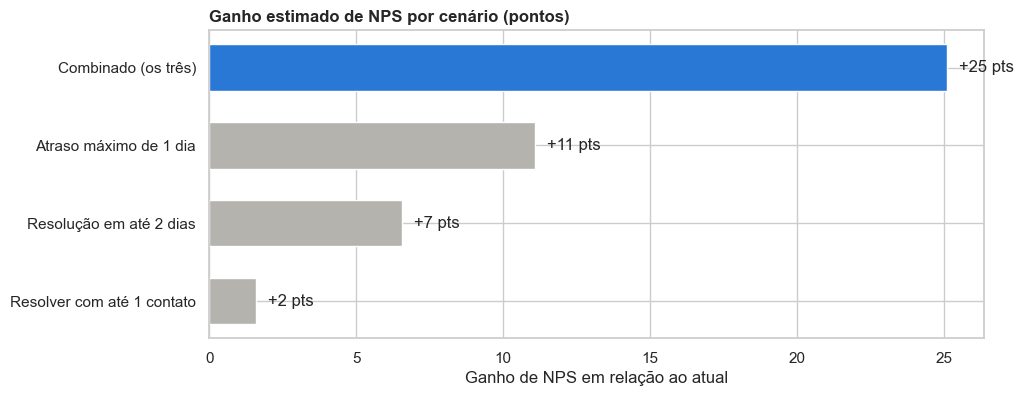

In [15]:
ganhos = tabela_cenarios.drop("Situação atual").sort_values("ganho vs atual (pontos)")
figura, eixo = plt.subplots(figsize=(10, 4))
eixo.barh(ganhos.index, ganhos["ganho vs atual (pontos)"],
          color=[COR_AZUL if "Combinado" in nome else COR_CINZA for nome in ganhos.index], height=0.6)
for posicao, valor in enumerate(ganhos["ganho vs atual (pontos)"]):
    eixo.text(valor + 0.4, posicao, f"+{valor:.0f} pts", va="center")
eixo.set_title("Ganho estimado de NPS por cenário (pontos)")
eixo.set_xlabel("Ganho de NPS em relação ao atual")
salvar_figura(figura, "14_simulacao_cenarios.png")
plt.show()

**Leitura:** atacar o **atraso** é, isoladamente, a alavanca de maior retorno; o ganho mais expressivo vem da **combinação** de logística e atendimento. Mesmo no cenário combinado o NPS continua negativo, mostrando que **o problema é grande e exige um programa contínuo**, não uma ação pontual.

## 10. Salvando o modelo e exemplo de uso

In [16]:
# O modelo final é treinado com TODOS os dados (treino + teste) antes de ser salvo
modelo_producao = LinearRegression().fit(variaveis_entrada, nota)
PASTA_MODELOS.mkdir(parents=True, exist_ok=True)
joblib.dump(modelo_producao, PASTA_MODELOS / "modelo_nps.joblib")
print("Modelo salvo em models/modelo_nps.joblib")

# Exemplo: três pedidos "em andamento" (ainda sem nota NPS) sendo pontuados
pedidos_exemplo = pd.DataFrame([
    {"customer_age": 35, "customer_region": "Sudeste", "customer_tenure_months": 24, "order_value": 320.0, "items_quantity": 2,
     "discount_value": 20.0, "payment_installments": 3, "delivery_time_days": 7, "delivery_delay_days": 0, "freight_value": 30.0,
     "delivery_attempts": 1, "customer_service_contacts": 0, "resolution_time_days": 0, "complaints_count": 1},
    {"customer_age": 52, "customer_region": "Nordeste", "customer_tenure_months": 80, "order_value": 610.0, "items_quantity": 4,
     "discount_value": 35.0, "payment_installments": 6, "delivery_time_days": 9, "delivery_delay_days": 2, "freight_value": 45.0,
     "delivery_attempts": 2, "customer_service_contacts": 1, "resolution_time_days": 3, "complaints_count": 3},
    {"customer_age": 28, "customer_region": "Norte", "customer_tenure_months": 6, "order_value": 150.0, "items_quantity": 1,
     "discount_value": 5.0, "payment_installments": 1, "delivery_time_days": 12, "delivery_delay_days": 4, "freight_value": 50.0,
     "delivery_attempts": 3, "customer_service_contacts": 3, "resolution_time_days": 9, "complaints_count": 6},
], index=["Pedido A", "Pedido B", "Pedido C"])
pontuar_pedidos(modelo_producao, pedidos_exemplo)[
    ["delivery_delay_days", "complaints_count", "customer_service_contacts", "nota_prevista", "faixa_risco"]
]

Modelo salvo em models/modelo_nps.joblib


,delivery_delay_days,complaints_count,customer_service_contacts,nota_prevista,faixa_risco
Pedido A,0,1,0,8.9,Risco baixo
Pedido B,2,3,1,5.5,Risco moderado
Pedido C,4,6,3,0.8,Risco alto


## 11. Como a empresa usaria isso na prática

1. **Pontuação diária (ou a cada evento):** sempre que um pedido muda de situação (atrasou, cliente ligou, abriu reclamação), o modelo recalcula a nota prevista. O script `python -m src.prever` faz isso em lote;
2. **Fila priorizada:** pedidos em **risco alto** vão para uma fila do time de CX com ação humana; **risco moderado** dispara ações automáticas (mensagem proativa, novo prazo realista, canal prioritário);
3. **Gatilhos simples, derivados da EDA:** "pedido completou 1 dia de atraso" e "cliente abriu a 2ª reclamação" são os dois pontos de ruptura e devem disparar alertas mesmo sem o modelo;
4. **Painel de "NPS previsto":** acompanhar a nota média prevista e a % de pedidos em risco por região e transportadora, sem esperar a pesquisa;
5. **Monitoramento e re-treino (MLOps):** comparar mensalmente nota prevista × nota real; se o erro subir (nova transportadora, mudança na pesquisa), re-treinar.

### 11.1 Proposta de teste A/B para provar o valor (Aula 5 de Estatística)

Antes de escalar, a ação preventiva deve ser testada com grupo de controle:

| Item | Definição |
|---|---|
| **Pergunta** | O contato proativo com pedidos de risco alto/moderado reduz a proporção de detratores? |
| **Unidade e aleatorização** | Pedido em risco, sorteado 50% para o grupo B (recebe a ação) e 50% para o grupo A (fluxo atual) |
| **Métrica primária** | % de detratores na pesquisa de NPS (métricas secundárias: nota média, recompra em 30 dias, custo da ação) |
| **Hipóteses** | H₀: a % de detratores é igual nos dois grupos · H₁: a % de detratores é **menor** no grupo B (teste unilateral, pois só a redução interessa à decisão) |
| **Teste estatístico** | Teste Z para duas proporções, nível de significância de 5% e poder de 80% |
| **Tamanho e duração** | Calcular o tamanho de amostra a partir do efeito mínimo de interesse (ex.: −5 pontos percentuais de detratores) e manter o teste por ciclos completos de entrega |
| **Decisão** | Se B for melhor com significância estatística **e** prática (ganho que paga o custo da ação), escalar gradualmente |

## 12. Limitações do modelo

- Explica cerca de metade da variação da nota: **é um sinal de alerta, não uma sentença**;
- Aprende **associações**, não causas; os efeitos estimados devem ser validados com o teste A/B acima;
- A base não tem datas, canal, produto, transportadora nem o texto das reclamações, informações que provavelmente melhorariam o modelo;
- `complaints_count` e `resolution_time_days` só ficam completos ao final do atendimento; em produção o modelo deve usar o **valor acumulado até o momento** da previsão;
- Notas acima de ~8,5 são pouco previsíveis: o modelo é bom em detectar **risco**, não **encantamento**;
- Possível viés de seleção: só quem respondeu à pesquisa está na base.

As premissas, métricas e limitações do modelo estão resumidas em [`docs/model_card.md`](../docs/model_card.md).